# Instituto Federal do Espírito Santo (IFES) – Campus Serra
### Programa de Pós-Graduação em Computação Aplicada (PPComp) – Mestrado

**Disciplina:** Redes Neurais Artificiais (2026/2)
**Professor:** Francisco de Assis Boldt
**Aluno:** Leonardo Cruz de Andrade
**Data de entrega:** 18 de novembro de 2026

## Atividade 03 – Previsão de poluição do ar (PM2.5) em Pequim

Na Aula 09 as técnicas de *forecasting* foram aplicadas à base climática de Jena, para prever a temperatura 24 horas à frente. Aqui eu uso as mesmas técnicas em outra base: medições horárias de poluição e clima em Pequim, com o objetivo de prever a concentração de PM2.5 com 24 horas de antecedência. Como referência, uso um método ingênuo (*naive*) que repete o valor de 24 horas antes.

**Organização do notebook**
1. A base de dados
2. Carregamento e valores ausentes
3. Um olhar sobre a série
4. Parâmetros do dataset e divisão treino/validação/teste
5. Baselines ingênuos
6. Modelos da aula
7. Comparação no conjunto de teste
8. Previsões ao longo do tempo
9. Conclusões

Código de referência da disciplina: [fboldt/aulasann](https://github.com/fboldt/aulasann) (`aula09a_forecasting`).

### Ambiente de execução

As saídas deste notebook foram geradas em CPU, com Python 3.10.4 e as versões abaixo. Para obter os mesmos números, crie um ambiente novo com Python 3.10 e Jupyter e instale:

```
pip install numpy==2.2.6 pandas==2.3.3 matplotlib==3.10.6 tensorflow==2.21.0 keras==3.12.4
```

A célula seguinte compara essas versões com as instaladas. Com outras versões (no Colab, por exemplo) o notebook roda normalmente, mas os resultados podem mudar nas últimas casas decimais.

O arquivo `pollution.csv` é baixado automaticamente na primeira execução (cerca de 2 MB).

In [1]:
from importlib.metadata import version, PackageNotFoundError
import platform

# versões usadas para gerar as saídas deste notebook
VERSOES_USADAS = {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "matplotlib": "3.10.6",
    "tensorflow": "2.21.0",
    "keras": "3.12.4",
}

diferentes = 0 if platform.python_version().startswith("3.10.") else 1
print(f"{'Python':16s} usada 3.10.4     instalada {platform.python_version()}")
for pacote, usada in VERSOES_USADAS.items():
    try:
        instalada = version(pacote)
    except PackageNotFoundError:
        instalada = "não instalado"
    igual = instalada.split("+")[0] == usada
    diferentes += not igual
    print(f"{pacote:16s} usada {usada:10s} instalada {instalada}{'' if igual else '   <- diferente'}")

if diferentes == 0:
    print("\nambiente igual ao usado nas saídas")
else:
    print(f"\n{diferentes} item(ns) com versão diferente: os números podem variar nas últimas casas")

Python           usada 3.10.4     instalada 3.10.4
numpy            usada 2.2.6      instalada 2.2.6
pandas           usada 2.3.3      instalada 2.3.3
matplotlib       usada 3.10.6     instalada 3.10.6
tensorflow       usada 2.21.0     instalada 2.21.0
keras            usada 3.12.4     instalada 3.12.4

ambiente igual ao usado nas saídas


## 1. A base de dados

A base é a *Beijing PM2.5 Data* do repositório UCI (Liang et al., 2015). São 43.824 registros horários de 1º/1/2010 a 31/12/2014 com:

- **`pm2.5`**: concentração de partículas finas (diâmetro menor que 2,5 µm) em µg/m³, medida na Embaixada dos EUA em Pequim. É a variável que quero prever.
- **Clima**, medido no Aeroporto Internacional de Pequim:
  - ponto de orvalho (`DEWP`, °C), temperatura (`TEMP`, °C) e pressão (`PRES`, hPa);
  - direção do vento agrupada (`cbwd`: NE, NW, SE e `cv`, calmo ou variável) e velocidade do vento acumulada (`Iws`, m/s);
  - horas acumuladas de neve (`Is`) e de chuva (`Ir`).

Em resumo, é uma série multivariada como a de Jena, mas com uma amostra por hora em vez de uma a cada 10 minutos, e com um alvo bem mais irregular que a temperatura.

In [2]:
import os
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import timeseries_dataset_from_array

SEED = 42
keras.utils.set_random_seed(SEED)           # Python, NumPy e TensorFlow
tf.config.experimental.enable_op_determinism()

# Os resultados do texto foram obtidos em CPU; em GPU os números mudam um pouco.
# Para usar a GPU, troque USAR_GPU para True.
USAR_GPU = False
if not USAR_GPU:
    tf.config.set_visible_devices([], "GPU")

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.12.4


## 2. Carregamento e valores ausentes

O CSV fica na pasta `data/`. Se não estiver lá, é baixado da cópia mantida por Jason Brownlee no GitHub, que é o mesmo arquivo da UCI.

O PM2.5 tem 2.067 horas sem medição (4,7%). A maior parte são lacunas curtas, mas há 20 lacunas com mais de 24 horas, e a maior tem 155 horas. Como a janela deslizante precisa de uma série contínua, preencho as lacunas por interpolação linear. As primeiras 24 horas, que não têm valor anterior para interpolar, recebem o primeiro valor medido. Essa interpolação só serve para montar as **entradas**: na hora de calcular o erro, uso apenas as horas em que o PM2.5 foi medido de fato, para não avaliar os modelos contra valores que eu mesmo inventei.

A direção do vento é categórica e vira quatro colunas binárias (*one-hot*).

In [3]:
DATA_DIR = "data"
CSV = os.path.join(DATA_DIR, "pollution.csv")
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"

if not os.path.exists(CSV):
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV)
    print("baixado de", URL)

df = pd.read_csv(CSV)
df.index = pd.to_datetime(df[["year", "month", "day", "hour"]])
print(df.shape[0], "registros, de", df.index[0], "a", df.index[-1])

pm_medido = df["pm2.5"].to_numpy(dtype="float32")         # com NaN, usado para avaliar
observado = ~np.isnan(pm_medido)
print(f"horas sem PM2.5: {(~observado).sum()} ({(~observado).mean():.1%})")

df["pm2.5"] = df["pm2.5"].interpolate().bfill()
vento = pd.get_dummies(df["cbwd"], prefix="vento", dtype="float32")
features = pd.concat([df[["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]], vento], axis=1)
print("atributos de entrada:", list(features.columns))
features.head()

baixado de https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv
43824 registros, de 2010-01-01 00:00:00 a 2014-12-31 23:00:00
horas sem PM2.5: 2067 (4.7%)
atributos de entrada: ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'vento_NE', 'vento_NW', 'vento_SE', 'vento_cv']


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,vento_NE,vento_NW,vento_SE,vento_cv
2010-01-01 00:00:00,129.0,-21,-11.0,1021.0,1.79,0,0,0.0,1.0,0.0,0.0
2010-01-01 01:00:00,129.0,-21,-12.0,1020.0,4.92,0,0,0.0,1.0,0.0,0.0
2010-01-01 02:00:00,129.0,-21,-11.0,1019.0,6.71,0,0,0.0,1.0,0.0,0.0
2010-01-01 03:00:00,129.0,-21,-14.0,1019.0,9.84,0,0,0.0,1.0,0.0,0.0
2010-01-01 04:00:00,129.0,-20,-12.0,1018.0,12.97,0,0,0.0,1.0,0.0,0.0


## 3. Um olhar sobre a série

Assim como na aula, olho a série inteira e um trecho de 10 dias. Também calculo a autocorrelação do PM2.5, isto é, a correlação da série com ela mesma deslocada de $k$ horas, que vai ajudar a escolher o tamanho da janela.

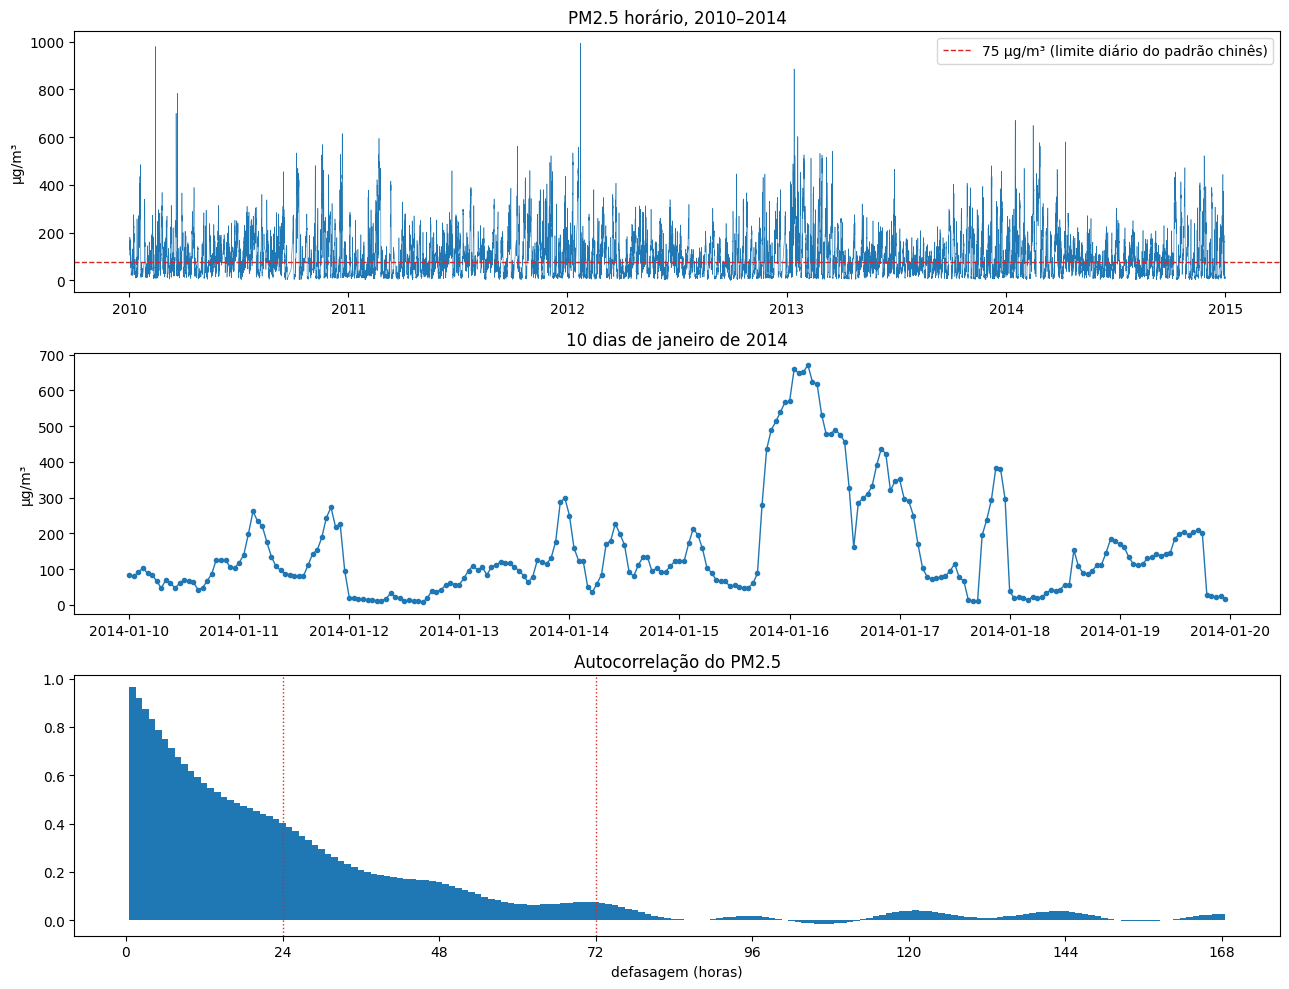

autocorrelação: 1 h: 0.97, 6 h: 0.75, 12 h: 0.57, 24 h: 0.40, 48 h: 0.16, 72 h: 0.07, 96 h: 0.02
PM2.5 medido (µg/m³): {'count': 41757.0, 'mean': 98.6, 'std': 92.1, 'min': 0.0, '25%': 29.0, '50%': 72.0, '75%': 137.0, 'max': 994.0}


In [4]:
pm = df["pm2.5"].to_numpy()

fig, axes = plt.subplots(3, 1, figsize=(13, 10))
axes[0].plot(df.index, pm, linewidth=0.4)
axes[0].axhline(75, color="tab:red", linestyle="--", linewidth=1, label="75 µg/m³ (limite diário do padrão chinês)")
axes[0].set_title("PM2.5 horário, 2010–2014")
axes[0].set_ylabel("µg/m³")
axes[0].legend(loc="upper right")

trecho = df.loc["2014-01-10":"2014-01-19"]
axes[1].plot(trecho.index, trecho["pm2.5"], ".-", linewidth=1)
axes[1].set_title("10 dias de janeiro de 2014")
axes[1].set_ylabel("µg/m³")

lags = np.arange(1, 169)
acf = [np.corrcoef(pm[:-k], pm[k:])[0, 1] for k in lags]
axes[2].bar(lags, acf, width=1)
for k in (24, 72):
    axes[2].axvline(k, color="tab:red", linestyle=":", linewidth=1)
axes[2].set_title("Autocorrelação do PM2.5")
axes[2].set_xlabel("defasagem (horas)")
axes[2].set_xticks([0, 24, 48, 72, 96, 120, 144, 168])
plt.tight_layout()
plt.show()

print("autocorrelação:", ", ".join(f"{k} h: {acf[k - 1]:.2f}" for k in (1, 6, 12, 24, 48, 72, 96)))
print("PM2.5 medido (µg/m³):", pd.Series(pm_medido).describe().round(1).to_dict())

O comportamento é bem diferente do da temperatura em Jena:
- **Episódios de poluição.** A série é feita de episódios: o PM2.5 sobe por dois ou três dias e despenca em poucas horas, normalmente quando muda o vento. A mediana é 72 µg/m³, mas há picos perto de 1.000.
- **Sazonalidade.** Os invernos são piores, por causa do aquecimento a carvão.
- **Memória curta.** A autocorrelação cai rápido: 0,97 com 1 hora de defasagem, 0,40 com 24 horas e menos de 0,1 a partir de 72 horas. Isso já sugere que prever 24 horas à frente é difícil e que olhar mais de 3 dias para trás traz pouca informação.

## 4. Parâmetros do dataset e divisão treino/validação/teste

O dataset é gerado com `timeseries_dataset_from_array`, como na aula. Os parâmetros que usei são os seguintes.

| Parâmetro | Aula (Jena) | Aqui | Justificativa |
| :--- | :---: | :---: | :--- |
| `sampling_rate` | 6 | 1 | Em Jena há uma leitura a cada 10 minutos, e `sampling_rate=6` pega uma por hora. Aqui os dados já são horários, então uso todas as amostras. |
| `sequence_length` | 120 | 72 | São 3 dias de histórico. Pela autocorrelação, depois de 72 h a série praticamente não se correlaciona mais com ela mesma, e 72 h cobrem a duração típica de um episódio de poluição. Janelas maiores aumentariam o custo do treino sem trazer informação relevante. |
| `delay` | `6 * (120 + 24 - 1)` | `1 * (72 + 24 - 1) = 95` | Com essa fórmula, o alvo fica 24 horas depois da última hora da janela. A janela que começa no índice $t$ cobre as horas $t, \dots, t+71$, e o alvo é o PM2.5 na hora $t+95$. |
| `batch_size` | 256 | 128 | A base é cerca de 10 vezes menor que a de Jena. Com 128, ficam por volta de 170 atualizações de pesos por época. |
| `shuffle` | treino | treino | Embaralho só a ordem das janelas no treino. Cada janela continua contínua no tempo, e validação e teste ficam em ordem. |

**Divisão no tempo.** Uso a mesma proporção da aula: 50% iniciais para treino (jan/2010 a jun/2012), os 20% seguintes para validação (jul/2012 a jun/2013) e os 30% finais para teste (jul/2013 a dez/2014). A divisão é feita sem embaralhar, para que o modelo nunca seja avaliado em um período anterior ao que usou para treinar.

**Normalização.** Média e desvio padrão são calculados só no trecho de treino, como na aula. Uma diferença em relação à aula é que o alvo também vai normalizado. Na aula o alvo era a temperatura em °C, com valores pequenos. Aqui o PM2.5 vai de 0 a quase 1.000, e a saída da rede levaria muitas épocas só para chegar à escala certa. Para reportar os erros em µg/m³, basta desfazer a normalização.

In [5]:
raw_data = features.to_numpy(dtype="float32")
n_samples = len(raw_data)
num_train_samples = int(0.5 * n_samples)
num_val_samples = int(0.2 * n_samples)
num_test_samples = n_samples - num_train_samples - num_val_samples

mean = raw_data[:num_train_samples].mean(axis=0)
std = raw_data[:num_train_samples].std(axis=0)
std[std == 0] = 1.0
data = (raw_data - mean) / std
alvo = data[:, 0]                       # PM2.5 normalizado
MU, SIGMA = mean[0], std[0]

sampling_rate = 1
sequence_length = 72
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 128

def gerar(targets, inicio, fim=None, shuffle=False):
    return timeseries_dataset_from_array(
        data[:-delay], targets=targets[delay:],
        sampling_rate=sampling_rate, sequence_length=sequence_length,
        shuffle=shuffle, seed=SEED, batch_size=batch_size,
        start_index=inicio, end_index=fim)

limites = {"treino": (0, num_train_samples),
           "validação": (num_train_samples, num_train_samples + num_val_samples),
           "teste": (num_train_samples + num_val_samples, None)}

train_dataset = gerar(alvo, *limites["treino"], shuffle=True)
val_dataset = gerar(alvo, *limites["validação"])
test_dataset = gerar(alvo, *limites["teste"])

# Mesmo janelamento, mas com o índice da hora como "alvo": diz a qual hora
# corresponde cada previsão, para avaliar só nas horas medidas.
indice_hora = np.arange(n_samples)
idx_alvo = {nome: np.concatenate([y.numpy() for _, y in gerar(indice_hora, *lim)])
            for nome, lim in limites.items() if nome != "treino"}

for nome, (ini, fim) in limites.items():
    fim = fim or n_samples
    print(f"{nome:10s} {fim - ini:6d} horas  {df.index[ini]:%d/%m/%Y} a {df.index[fim - 1]:%d/%m/%Y}")

x, y = next(iter(train_dataset))
print("\nlote de treino:", x.shape, "->", y.shape, "| delay =", delay)

# conferência do alinhamento: o alvo da 1ª janela de teste é a hora 95 depois do início da janela
ini_teste = limites["teste"][0]
x0, y0 = next(iter(test_dataset))
assert idx_alvo["teste"][0] == ini_teste + delay
assert np.isclose(y0[0], alvo[ini_teste + delay]) and np.isclose(x0[0, -1, 0], alvo[ini_teste + sequence_length - 1])
print("1ª janela de teste: entradas", df.index[ini_teste], "a", df.index[ini_teste + sequence_length - 1],
      "| alvo", df.index[idx_alvo["teste"][0]])

treino      21912 horas  01/01/2010 a 01/07/2012
validação    8764 horas  02/07/2012 a 02/07/2013
teste       13148 horas  02/07/2013 a 31/12/2014

lote de treino: (128, 72, 11) -> (128,) | delay = 95
1ª janela de teste: entradas 2013-07-02 04:00:00 a 2013-07-05 03:00:00 | alvo 2013-07-06 03:00:00


## 5. Baselines ingênuos

O baseline da aula prevê que o valor daqui a 24 horas será igual ao último valor observado na janela:

$$\hat{y}_{t+24} = y_t$$

Neste problema esse baseline tem uma interpretação extra. Como o horizonte é exatamente 24 horas, ele também é o "ingênuo sazonal" diário: prevê para amanhã às 15h o que foi medido hoje às 15h.

Incluí um segundo baseline igualmente simples: a média das últimas 24 horas da janela. Como o PM2.5 oscila muito de uma hora para outra, era de esperar que suavizar ajudasse. Se as redes não baterem pelo menos esses dois, não vale a pena usá-las.

As métricas são o erro médio absoluto (MAE), a mesma da aula, e a raiz do erro quadrático médio (RMSE), que pesa mais os erros grandes. As duas estão em µg/m³ e são calculadas só nas horas com medição real.

In [6]:
def metricas(pred, nome_conjunto):
    idx = idx_alvo[nome_conjunto]
    ok = observado[idx]
    erro = pred[ok] - pm_medido[idx][ok]
    return np.mean(np.abs(erro)), np.sqrt(np.mean(erro ** 2))

def naive(nome_conjunto):
    idx = idx_alvo[nome_conjunto]
    return pm[idx - 24]                    # última hora da janela

def media_24h(nome_conjunto):
    idx = idx_alvo[nome_conjunto]
    return np.array([pm[i - 47:i - 23].mean() for i in idx])

# a previsão ingênua coincide com samples[:, -1, 0] desnormalizado, como na aula
amostra = np.concatenate([x[:, -1, 0].numpy() for x, _ in test_dataset]) * SIGMA + MU
assert np.allclose(amostra, naive("teste"), atol=1e-2)

resultados = {}
for nome, f in [("Naive (valor de 24 h antes)", naive), ("Média das últimas 24 h", media_24h)]:
    resultados[nome] = {"val": metricas(f("validação"), "validação"), "teste": metricas(f("teste"), "teste"),
                        "params": 0, "epoca": None, "pred_teste": f("teste")}
    (vm, vr), (tm, tr) = resultados[nome]["val"], resultados[nome]["teste"]
    print(f"{nome:28s} validação: MAE {vm:6.2f}  RMSE {vr:6.2f} | teste: MAE {tm:6.2f}  RMSE {tr:6.2f}")

print(f"\nhoras avaliadas: validação {observado[idx_alvo['validação']].sum()} de {len(idx_alvo['validação'])}, "
      f"teste {observado[idx_alvo['teste']].sum()} de {len(idx_alvo['teste'])}")

Naive (valor de 24 h antes)  validação: MAE  77.08  RMSE 111.14 | teste: MAE  66.50  RMSE  97.28
Média das últimas 24 h       validação: MAE  81.76  RMSE 109.96 | teste: MAE  72.91  RMSE 101.94

horas avaliadas: validação 8324 de 8693, teste 12836 de 12982


A média das últimas 24 horas, ao contrário do que eu esperava, erra mais que o naive. O motivo é o ciclo diário: o naive repete a mesma hora do dia anterior e por isso acompanha o padrão dia/noite, enquanto a média apaga esse padrão. Fica valendo como referência principal o naive da aula, com MAE de 66,5 µg/m³ no teste.

## 6. Modelos da aula

Treino as mesmas arquiteturas da `aula09a`, com 16 unidades como lá, além da SimpleRNN que também foi apresentada na aula:

1. **Densa:** `Flatten` e uma camada `Dense(16)`. Trata a janela como um vetor e ignora a ordem das horas.
2. **Conv1D:** três convoluções 1D com *pooling*, como na aula. Os filtros têm 24, 12 e 6 passos, o que com uma janela de 72 h deixa exatamente uma posição na última camada.
3. **SimpleRNN(16).**
4. **LSTM(16).**
5. **LSTM(16) + Dropout(0,5).**
6. **LSTM bidirecional(16) + Dropout(0,5).**

O treino segue o da aula: RMSprop, custo MSE, métrica MAE, 10 épocas e `ModelCheckpoint(save_best_only=True)`, que guarda o modelo da época com menor custo de validação. É esse modelo que vai para o teste. Para tornar os resultados reprodutíveis, fixei as sementes e ativei o modo determinístico do TensorFlow, então rodar o notebook de novo dá os mesmos números.

In [7]:
n_features = raw_data.shape[-1]
os.makedirs("modelos", exist_ok=True)

def densa():
    inputs = keras.Input(shape=(sequence_length, n_features))
    x = layers.Flatten()(inputs)
    x = layers.Dense(16, activation="relu")(x)
    return keras.Model(inputs, layers.Dense(1)(x))

def conv1d():
    inputs = keras.Input(shape=(sequence_length, n_features))
    x = layers.Conv1D(8, 24, activation="relu")(inputs)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(8, 12, activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(8, 6, activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    return keras.Model(inputs, layers.Dense(1)(x))

def simple_rnn():
    inputs = keras.Input(shape=(sequence_length, n_features))
    return keras.Model(inputs, layers.Dense(1)(layers.SimpleRNN(16)(inputs)))

def lstm():
    inputs = keras.Input(shape=(sequence_length, n_features))
    return keras.Model(inputs, layers.Dense(1)(layers.LSTM(16)(inputs)))

def lstm_dropout():
    inputs = keras.Input(shape=(sequence_length, n_features))
    x = layers.Dropout(0.5)(layers.LSTM(16)(inputs))
    return keras.Model(inputs, layers.Dense(1)(x))

def bilstm_dropout():
    inputs = keras.Input(shape=(sequence_length, n_features))
    x = layers.Dropout(0.5)(layers.Bidirectional(layers.LSTM(16))(inputs))
    return keras.Model(inputs, layers.Dense(1)(x))

def treinar(nome, construtor, epochs=10):
    keras.utils.set_random_seed(SEED)
    model = construtor()
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    arquivo = os.path.join("modelos", nome.replace(" ", "_") + ".keras")
    inicio = time.time()
    hist = model.fit(train_dataset, epochs=epochs, validation_data=val_dataset, verbose=0,
                     callbacks=[keras.callbacks.ModelCheckpoint(arquivo, save_best_only=True)])
    model = keras.models.load_model(arquivo)
    pred_val = model.predict(val_dataset, verbose=0).ravel() * SIGMA + MU
    pred_teste = model.predict(test_dataset, verbose=0).ravel() * SIGMA + MU
    melhor = int(np.argmin(hist.history["val_loss"])) + 1
    resultados[nome] = {"val": metricas(pred_val, "validação"), "teste": metricas(pred_teste, "teste"),
                        "params": model.count_params(), "epoca": melhor,
                        "hist": hist.history, "pred_teste": pred_teste}
    (vm, _), (tm, tr) = resultados[nome]["val"], resultados[nome]["teste"]
    print(f"{nome:22s} {time.time() - inicio:5.0f} s | melhor época {melhor:2d} | "
          f"validação MAE {vm:6.2f} | teste MAE {tm:6.2f}  RMSE {tr:6.2f}")

modelos = {"Densa": densa, "Conv1D": conv1d, "SimpleRNN": simple_rnn, "LSTM": lstm,
           "LSTM + dropout": lstm_dropout, "LSTM bidirecional": bilstm_dropout}
for nome, construtor in modelos.items():
    treinar(nome, construtor)

Densa                      8 s | melhor época  6 | validação MAE  69.67 | teste MAE  64.88  RMSE  87.02


Conv1D                    13 s | melhor época  1 | validação MAE  75.58 | teste MAE  71.43  RMSE  92.49


SimpleRNN                 17 s | melhor época  9 | validação MAE  65.26 | teste MAE  60.04  RMSE  81.43


LSTM                      33 s | melhor época  2 | validação MAE  65.89 | teste MAE  60.60  RMSE  81.51


LSTM + dropout            33 s | melhor época  8 | validação MAE  64.76 | teste MAE  61.07  RMSE  83.36


LSTM bidirecional         38 s | melhor época  4 | validação MAE  66.52 | teste MAE  61.94  RMSE  82.45


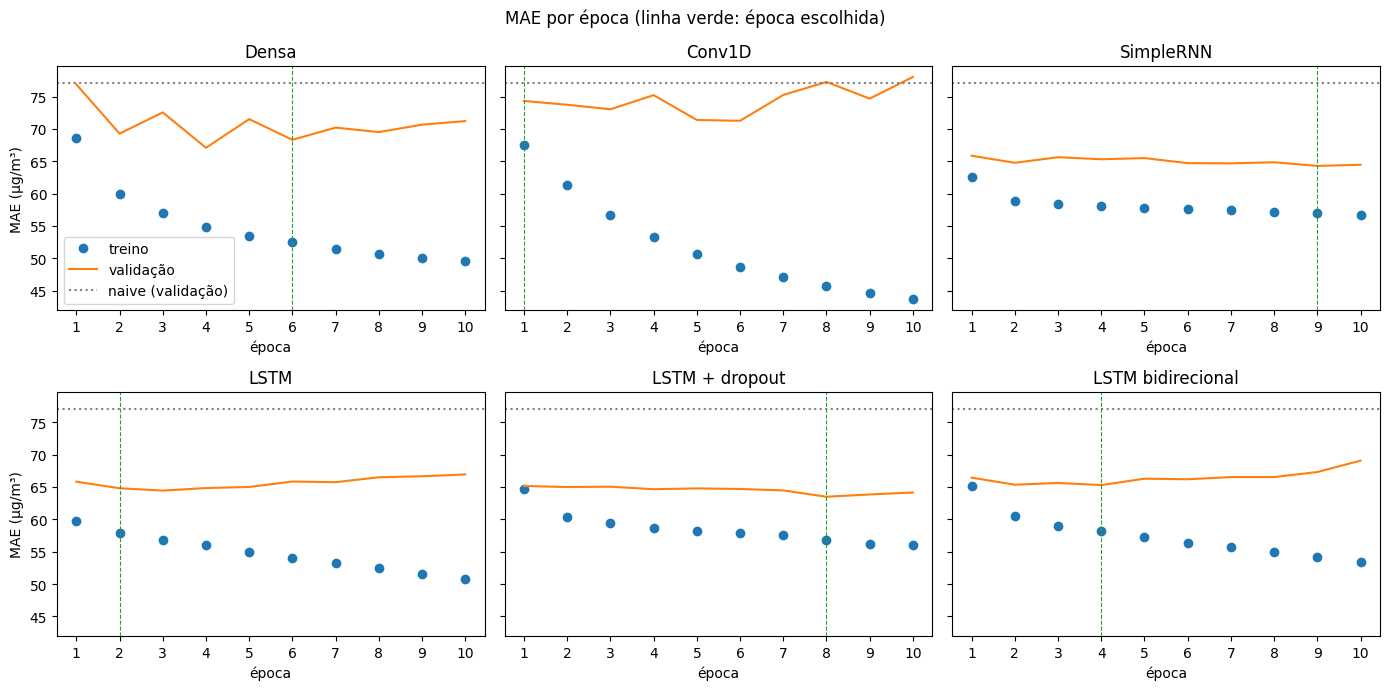

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
naive_val = resultados["Naive (valor de 24 h antes)"]["val"][0]
for ax, nome in zip(axes.flat, modelos):
    h = resultados[nome]["hist"]
    ep = np.arange(1, len(h["mae"]) + 1)
    ax.plot(ep, np.array(h["mae"]) * SIGMA, "o", label="treino")
    ax.plot(ep, np.array(h["val_mae"]) * SIGMA, "-", label="validação")
    ax.axhline(naive_val, color="gray", linestyle=":", label="naive (validação)")
    ax.axvline(resultados[nome]["epoca"], color="tab:green", linestyle="--", linewidth=0.8)
    ax.set_title(nome)
    ax.set_xlabel("época")
    ax.set_xticks(ep)
axes[0, 0].set_ylabel("MAE (µg/m³)")
axes[1, 0].set_ylabel("MAE (µg/m³)")
axes[0, 0].legend()
fig.suptitle("MAE por época (linha verde: época escolhida)")
plt.tight_layout()
plt.show()

O que as curvas mostram:
- **Densa e Conv1D.** O erro de treino cai bastante, mas o de validação oscila e não acompanha: as duas decoram o período de treino. A Conv1D chega ao melhor resultado já na 1ª época e piora depois.
- **Redes recorrentes.** O MAE de validação varia pouco, entre 63 e 69 µg/m³, e fica sempre abaixo do naive.
- **LSTM sem *dropout*.** Começa a sobreajustar depois da 2ª ou 3ª época. Com *dropout*, a validação se mantém até o fim, e a melhor época passa a ser a 8ª.

Em todos os casos o `ModelCheckpoint` evita que o sobreajuste das últimas épocas chegue ao teste.

## 7. Comparação no conjunto de teste

A tabela reúne os dois baselines e os seis modelos. O ganho é a redução do MAE em relação ao naive da aula.

,MAE validação,MAE teste,RMSE teste,ganho sobre o naive (%),parâmetros,época
modelo,,,,,,
Naive (valor de 24 h antes),77.08,66.50,97.28,+0.0,0,
Média das últimas 24 h,81.76,72.91,101.94,-9.6,0,
Densa,69.67,64.88,87.02,+2.4,12705,6
Conv1D,75.58,71.43,92.49,-7.4,3297,1
SimpleRNN,65.26,60.04,81.43,+9.7,465,9
LSTM,65.89,60.60,81.51,+8.9,1809,2
LSTM + dropout,64.76,61.07,83.36,+8.2,1809,8
LSTM bidirecional,66.52,61.94,82.45,+6.9,3617,4


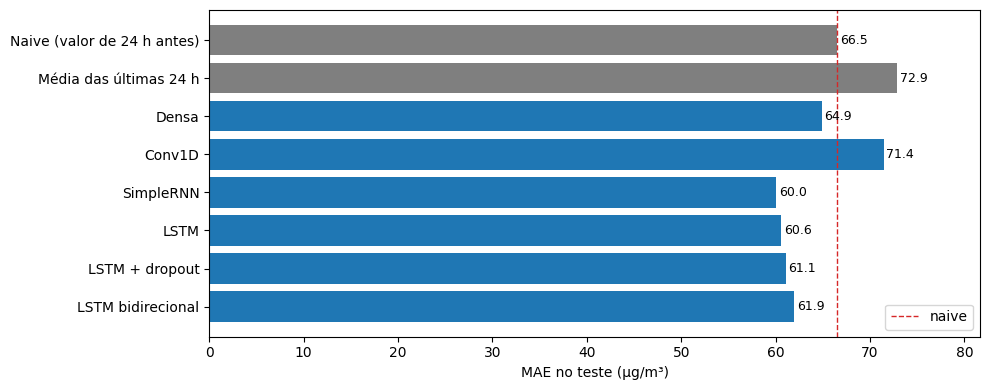

In [9]:
mae_naive = resultados["Naive (valor de 24 h antes)"]["teste"][0]
tabela = pd.DataFrame([
    {"modelo": nome,
     "MAE validação": r["val"][0],
     "MAE teste": r["teste"][0],
     "RMSE teste": r["teste"][1],
     "ganho sobre o naive (%)": 100 * (mae_naive - r["teste"][0]) / mae_naive,
     "parâmetros": r["params"],
     "época": r["epoca"]}
    for nome, r in resultados.items()
]).set_index("modelo")
display(tabela.style.format({"MAE validação": "{:.2f}", "MAE teste": "{:.2f}", "RMSE teste": "{:.2f}",
                             "ganho sobre o naive (%)": "{:+.1f}", "época": lambda v: "" if pd.isna(v) else f"{v:.0f}"}))

fig, ax = plt.subplots(figsize=(10, 4))
cores = ["tab:gray"] * 2 + ["tab:blue"] * (len(tabela) - 2)
ax.barh(tabela.index[::-1], tabela["MAE teste"][::-1], color=cores[::-1])
ax.axvline(mae_naive, color="tab:red", linestyle="--", linewidth=1, label="naive")
for i, v in enumerate(tabela["MAE teste"][::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlabel("MAE no teste (µg/m³)")
ax.set_xlim(0, tabela["MAE teste"].max() * 1.12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Previsões ao longo do tempo

Os números médios não mostram *como* cada método erra. No gráfico abaixo comparo, num trecho de duas semanas do teste, a série real, o naive e o melhor modelo segundo a validação.

melhor rede pela validação: LSTM + dropout


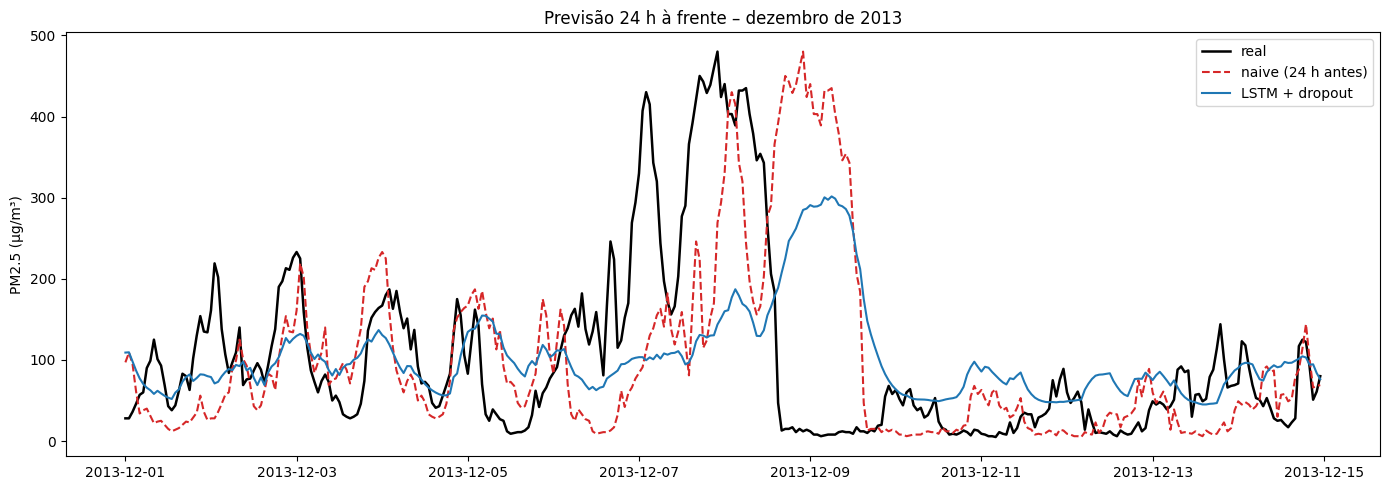

,horas,MAE naive,MAE LSTM + dropout
PM2.5 real (µg/m³),,,
0–35,3717,70.1,77.6
35–75,3132,43.7,38.4
75–150,3510,54.1,27.0
150–1000,2477,107.6,113.3


In [10]:
redes = list(modelos)
melhor_rede = min(redes, key=lambda n: resultados[n]["val"][0])
print("melhor rede pela validação:", melhor_rede)

idx = idx_alvo["teste"]
datas = df.index[idx]
janela = (datas >= "2013-12-01") & (datas < "2013-12-15")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datas[janela], pm_medido[idx][janela], "k-", linewidth=1.8, label="real")
ax.plot(datas[janela], resultados["Naive (valor de 24 h antes)"]["pred_teste"][janela], "--",
        color="tab:red", label="naive (24 h antes)")
ax.plot(datas[janela], resultados[melhor_rede]["pred_teste"][janela], color="tab:blue", label=melhor_rede)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Previsão 24 h à frente – dezembro de 2013")
ax.legend()
plt.tight_layout()
plt.show()

# erro por faixa de poluição real
faixas = [0, 35, 75, 150, 1000]
real = pm_medido[idx].astype("float64")
ok = observado[idx]
linhas = []
for a, b in zip(faixas[:-1], faixas[1:]):
    m = ok & (real >= a) & (real < b)
    linhas.append({"PM2.5 real (µg/m³)": f"{a}–{b}", "horas": int(m.sum()),
                   "MAE naive": np.mean(np.abs(resultados["Naive (valor de 24 h antes)"]["pred_teste"][m] - real[m])),
                   f"MAE {melhor_rede}": np.mean(np.abs(resultados[melhor_rede]["pred_teste"][m] - real[m]))})
display(pd.DataFrame(linhas).set_index("PM2.5 real (µg/m³)").round(1))

O gráfico mostra bem a diferença entre os dois métodos:
- **Naive.** É a série real deslocada 24 horas para a direita. Acerta quando o dia seguinte se parece com o anterior, mas erra feio nas viradas. No episódio de 7 a 9 de dezembro ele "prevê" o pico de 450 µg/m³ justamente no dia em que o ar já tinha limpado.
- **LSTM.** Também não antecipa a queda brusca do dia 8; ela também chega com atraso. A diferença é que a previsão é mais conservadora: fica perto da média em dias normais e sobe só em parte durante os episódios.

A tabela por faixa confirma esse comportamento:
- **Faixa intermediária (35 a 150 µg/m³):** a rede erra bem menos que o naive.
- **Ar limpo (abaixo de 35):** a rede erra um pouco mais, porque superestima.
- **Episódios graves (acima de 150):** a rede também erra mais, porque subestima.

O ganho da rede vem de evitar os erros grandes do naive. Isso também explica por que a melhora no RMSE é maior que no MAE.

## 9. Conclusões

**Base e parâmetros.** A base de PM2.5 de Pequim é bem mais difícil que a temperatura de Jena: a autocorrelação com 24 horas de defasagem é só 0,40. Os parâmetros do `timeseries_dataset_from_array` foram adaptados da aula:
- `sampling_rate=1`, porque os dados já são horários;
- `sequence_length=72`, porque a autocorrelação praticamente some depois de 3 dias;
- `delay=95`, para o alvo ficar 24 h depois do fim da janela;
- `batch_size=128`, porque a base é menor.

**Baseline.** O naive ($\hat{y}_{t+24} = y_t$) teve MAE de 66,5 µg/m³ no teste. A média das últimas 24 h foi pior (72,9), porque perde o ciclo diário.

**Modelos.**
- **Recorrentes:** as quatro redes recorrentes bateram o naive, com MAE entre 60,0 e 61,9 µg/m³, uma redução de 7% a 10%. No RMSE a redução foi maior, de 14% a 16% (de 97,3 para 81,4–83,4). A diferença entre elas é pequena, menor que 2 µg/m³, e a ordem muda entre validação e teste: a melhor na validação foi a LSTM com *dropout*, e no teste a SimpleRNN. Com uma única execução, não dá para dizer que uma é melhor que a outra.
- **Densa:** ficou só um pouco melhor que o naive (64,9).
- **Conv1D:** foi pior que o naive (71,4) e sobreajustou já a partir da 2ª época. É o mesmo padrão da aula, em que a Conv1D também perdeu para o baseline em Jena.

**Limitações.**
- **Viradas bruscas:** nenhum modelo antecipou as quedas bruscas causadas por mudança de vento; todos chegam atrasados.
- **Previsões conservadoras:** as redes tendem a "puxar para a média", superestimando dias limpos e subestimando os piores episódios.
- **Possíveis melhorias:** usar a previsão do tempo para o dia seguinte como entrada, já que o vento é o que limpa o ar, ou prever o logaritmo do PM2.5, que reduziria o peso dos picos no custo.

---
Leonardo Cruz de Andrade – PPComp/IFES, Campus Serra
Redes Neurais Artificiais (2026/2) – Prof. Francisco de Assis Boldt